PyTorch version: 2.7.1+cu128
CUDA available: True
Устройство: cuda
🚀 ЗАПУСК СБАЛАНСИРОВАННОГО ОБУЧЕНИЯ...
loading annotations into memory...
Done (t=0.96s)
creating index...
index created!
loading annotations into memory...
Done (t=0.03s)
creating index...
index created!
Загружено 3000 изображений
Загружено 600 изображений
📊 Данные: 3000 train, 600 val
🧠 Сбалансированная модель создана
⚖️ Сбалансированная функция потерь активирована

⚖️ ЭПОХА 1/40
--------------------------------------------------


Balanced Training: 100%|██████████| 188/188 [02:11<00:00,  1.43it/s, Loss=0.4397, Dice=0.0033, OverPred=0.00x] 



📊 Эпоха 1 результаты:
📈 Train - Dice: 0.0098, OverPred: 0.37x
📈 Val   - Dice: 0.0008, OverPred: 0.01x
🎯 Detection Rate: 13.8%
📉 Learning Rate: 1.00e-03
💾 ЛУЧШАЯ МОДЕЛЬ! Dice: 0.0008
Image 4: True=336.0, Pred=0.0, Ratio=0.00x
Image 444: True=146.0, Pred=0.0, Ratio=0.00x
Image 495: True=3601.0, Pred=0.0, Ratio=0.00x
Image 555: True=16562.0, Pred=0.0, Ratio=0.00x


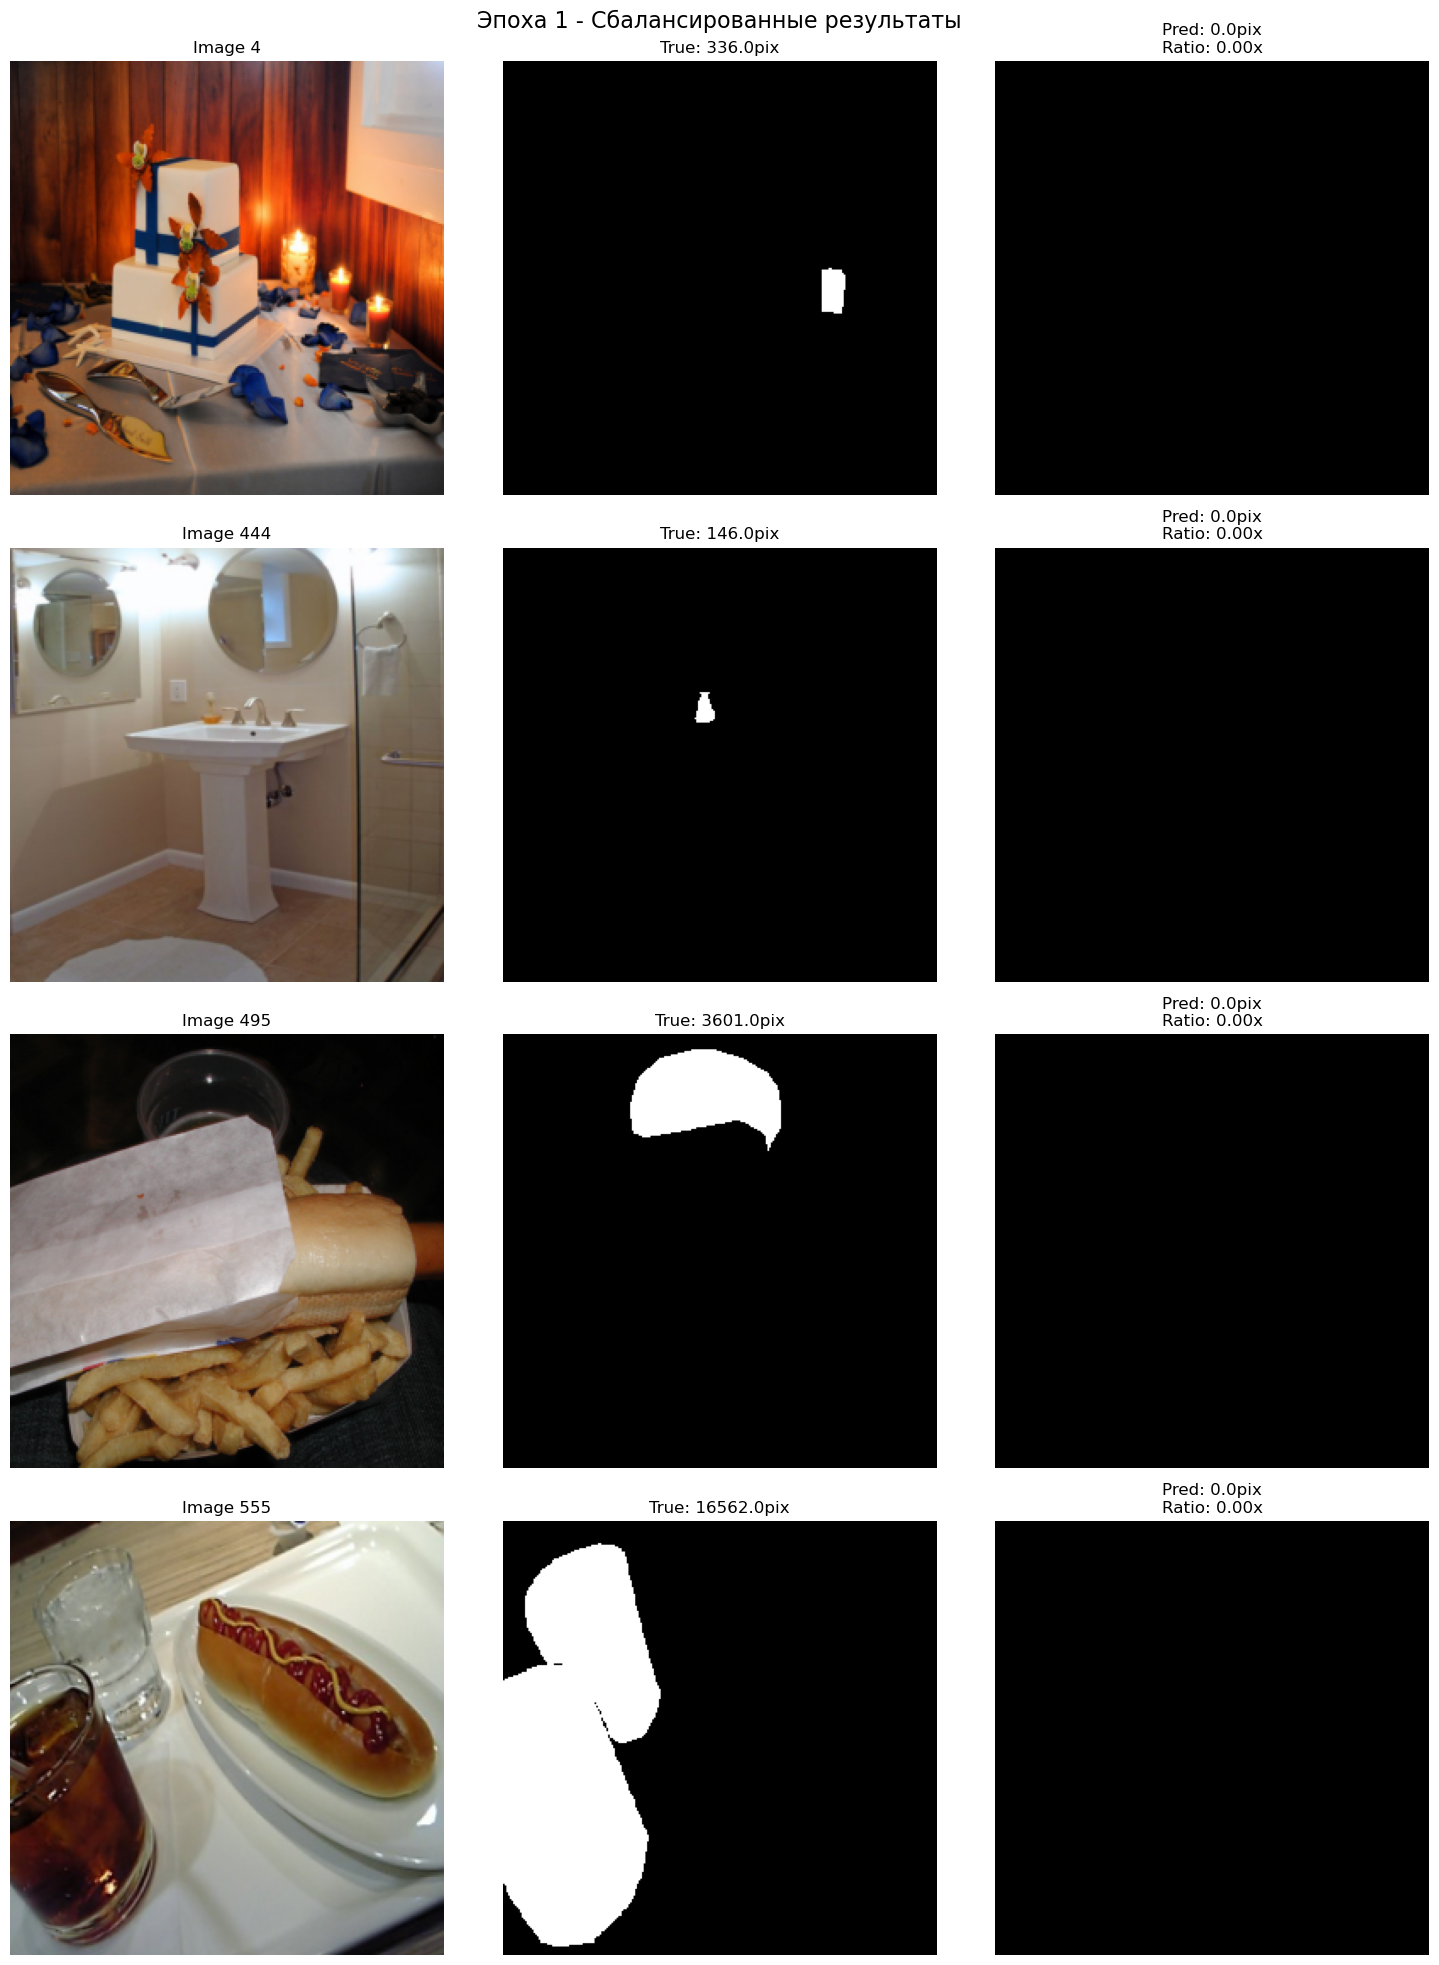


⚖️ ЭПОХА 2/40
--------------------------------------------------


Balanced Training: 100%|██████████| 188/188 [01:52<00:00,  1.67it/s, Loss=0.5554, Dice=0.0000, OverPred=0.00x]



📊 Эпоха 2 результаты:
📈 Train - Dice: 0.0001, OverPred: 0.00x
📈 Val   - Dice: 0.0000, OverPred: 0.00x
🎯 Detection Rate: 4.1%
📉 Learning Rate: 1.00e-03
⏳ Patience: 1/10

⚖️ ЭПОХА 3/40
--------------------------------------------------


Balanced Training: 100%|██████████| 188/188 [01:47<00:00,  1.75it/s, Loss=0.2605, Dice=0.0000, OverPred=0.00x]



📊 Эпоха 3 результаты:
📈 Train - Dice: 0.0003, OverPred: 0.00x
📈 Val   - Dice: 0.0001, OverPred: 0.01x
🎯 Detection Rate: 5.6%
📉 Learning Rate: 1.00e-03
⏳ Patience: 2/10

⚖️ ЭПОХА 4/40
--------------------------------------------------


Balanced Training: 100%|██████████| 188/188 [01:23<00:00,  2.24it/s, Loss=0.3902, Dice=0.0000, OverPred=0.00x]


... (11 outputs left out)

Balanced Training: 100%|██████████| 188/188 [01:29<00:00,  2.10it/s, Loss=0.0907, Dice=0.0000, OverPred=0.00x]



📊 Эпоха 10 результаты:
📈 Train - Dice: 0.0000, OverPred: 0.00x
📈 Val   - Dice: 0.0000, OverPred: 0.00x
🎯 Detection Rate: 4.1%
📉 Learning Rate: 5.00e-04
⏳ Patience: 9/10

⚖️ ЭПОХА 11/40
--------------------------------------------------


Balanced Training: 100%|██████████| 188/188 [01:24<00:00,  2.21it/s, Loss=0.3031, Dice=0.0000, OverPred=0.00x]



📊 Эпоха 11 результаты:
📈 Train - Dice: 0.0000, OverPred: 0.00x
📈 Val   - Dice: 0.0000, OverPred: 0.00x
🎯 Detection Rate: 4.1%
📉 Learning Rate: 5.00e-04
⏳ Patience: 10/10
🛑 Ранняя остановка после 11 эпох

🎉 СБАЛАНСИРОВАННОЕ ОБУЧЕНИЕ ЗАВЕРШЕНО!
🏆 Лучший Dice: 0.0008


In [3]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import random
import time
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from pycocotools.coco import COCO

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

# =============================================
# СБАЛАНСИРОВАННАЯ КОНФИГУРАЦИЯ
# =============================================

IMG_SIZE = (256, 256)
BATCH_SIZE = 16
EPOCHS = 40
LEARNING_RATE = 0.001
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

BASE_DIR = Path("archive/coco2017")
TRAIN_IMAGE_DIR = BASE_DIR / "filtered_train2017"
VAL_IMAGE_DIR = BASE_DIR / "filtered_val2017"
TRAIN_ANNOTATION = BASE_DIR / "annotations/filtered_train_annotations.json"
VAL_ANNOTATION = BASE_DIR / "annotations/filtered_val_annotations.json"

print(f"Устройство: {DEVICE}")

# =============================================
# СБАЛАНСИРОВАННАЯ ФУНКЦИЯ ПОТЕРЬ
# =============================================

class BalancedLoss(nn.Module):
    def __init__(self, fn_weight=2.0, fp_weight=1.5, smooth=1e-6):
        super().__init__()
        self.fn_weight = fn_weight
        self.fp_weight = fp_weight
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()
        
    def forward(self, pred, target):
        bce_loss = self.bce(pred, target)
        fn_loss = self.false_negative_loss(pred, target)
        fp_loss = self.false_positive_loss(pred, target)
        precision_loss = self.precision_control_loss(pred, target)
        
        total_loss = (bce_loss + 
                     self.fn_weight * fn_loss + 
                     self.fp_weight * fp_loss +
                     precision_loss)
        
        return total_loss
    
    def false_negative_loss(self, pred, target):
        pred_sigmoid = torch.sigmoid(pred)
        fn_mask = (target > 0.5) & (pred_sigmoid < 0.3)
        fn_ratio = fn_mask.float().mean()
        return fn_ratio ** 1.5
    
    def false_positive_loss(self, pred, target):
        pred_sigmoid = torch.sigmoid(pred)
        fp_mask = (target < 0.5) & (pred_sigmoid > 0.7)
        fp_ratio = fp_mask.float().mean()
        return fp_ratio ** 1.5
    
    def precision_control_loss(self, pred, target):
        pred_sigmoid = torch.sigmoid(pred)
        pred_pixels = pred_sigmoid.sum(dim=[1,2,3])
        true_pixels = target.sum(dim=[1,2,3])
        ratio = pred_pixels / (true_pixels + self.smooth)
        overflow_penalty = F.relu(ratio - 3.0).mean()
        return overflow_penalty

# =============================================
# ОПТИМИЗИРОВАННАЯ МОДЕЛЬ
# =============================================

class BalancedUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()
        
        self.enc1 = self._block(in_channels, 32)
        self.enc2 = self._block(32, 64)
        self.enc3 = self._block(64, 128)
        self.enc4 = self._block(128, 256)
        
        self.bottleneck = self._block(256, 512)
        
        self.up4 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec4 = self._block(512, 256)
        
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec3 = self._block(256, 128)
        
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec2 = self._block(128, 64)
        
        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec1 = self._block(64, 32)
        
        self.final = nn.Conv2d(32, out_channels, kernel_size=1)
        self.pool = nn.MaxPool2d(2)
        
        self.apply(self._init_weights)
        
    def _init_weights(self, module):
        if isinstance(module, nn.Conv2d):
            nn.init.kaiming_normal_(module.weight, mode='fan_out', nonlinearity='relu')
            if module.bias is not None:
                nn.init.constant_(module.bias, 0)
        elif isinstance(module, nn.BatchNorm2d):
            nn.init.constant_(module.weight, 1)
            nn.init.constant_(module.bias, 0)
    
    def _block(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
    
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        
        bottleneck = self.bottleneck(self.pool(e4))
        
        d4 = self.up4(bottleneck)
        d4 = torch.cat([e4, d4], dim=1)
        d4 = self.dec4(d4)
        
        d3 = self.up3(d4)
        d3 = torch.cat([e3, d3], dim=1)
        d3 = self.dec3(d3)
        
        d2 = self.up2(d3)
        d2 = torch.cat([e2, d2], dim=1)
        d2 = self.dec2(d2)
        
        d1 = self.up1(d2)
        d1 = torch.cat([e1, d1], dim=1)
        d1 = self.dec1(d1)
        
        return self.final(d1)

# =============================================
# ДАТАСЕТ И МЕТРИКИ
# =============================================

train_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomHorizontalFlip(0.3),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class COCODataset(Dataset):
    def __init__(self, coco, img_dir, transform=None, max_samples=None):
        self.coco = coco
        self.img_dir = img_dir
        self.transform = transform
        self.ids = list(coco.imgs.keys())
        
        if max_samples:
            self.ids = self.ids[:max_samples]
        
        print(f"Загружено {len(self.ids)} изображений")
        
    def __len__(self):
        return len(self.ids)
    
    def __getitem__(self, idx):
        img_id = self.ids[idx]
        img_info = self.coco.loadImgs(img_id)[0]
        
        img_path = self.img_dir / img_info['file_name']
        img = Image.open(img_path).convert('RGB')
        
        ann_ids = self.coco.getAnnIds(imgIds=img_id)
        anns = self.coco.loadAnns(ann_ids)
        mask = np.zeros((img_info['height'], img_info['width']), dtype=np.uint8)
        
        for ann in anns:
            mask = np.maximum(mask, self.coco.annToMask(ann) * 255)
        
        mask = Image.fromarray(mask)
        
        if self.transform:
            img = self.transform(img)
            mask = transforms.Resize(IMG_SIZE, Image.NEAREST)(mask)
            mask = transforms.ToTensor()(mask)
            mask = (mask > 0).float()
        
        return img, mask

def calculate_metrics(pred, target, threshold=0.5):
    pred_binary = (pred > threshold).float()
    
    dice = dice_coefficient(pred_binary, target)
    iou = iou_score(pred_binary, target)
    
    has_object = (target.sum(dim=[1,2,3]) > 50).float()
    detected = (pred_binary.sum(dim=[1,2,3]) > 25).float()
    detection_rate = (has_object == detected).float().mean()
    
    true_pixels = target.sum().item()
    pred_pixels = pred_binary.sum().item()
    
    if true_pixels > 0:
        overpred_ratio = pred_pixels / true_pixels
    else:
        overpred_ratio = 1.0
    
    return dice, iou, detection_rate, overpred_ratio

def dice_coefficient(pred, target, smooth=1e-6):
    pred_flat = pred.contiguous().view(-1)
    target_flat = target.contiguous().view(-1)
    intersection = (pred_flat * target_flat).sum()
    return (2. * intersection + smooth) / (pred_flat.sum() + target_flat.sum() + smooth)

def iou_score(pred, target, smooth=1e-6):
    pred_flat = pred.contiguous().view(-1)
    target_flat = target.contiguous().view(-1)
    intersection = (pred_flat * target_flat).sum()
    union = pred_flat.sum() + target_flat.sum() - intersection
    return (intersection + smooth) / (union + smooth)

# =============================================
# СБАЛАНСИРОВАННОЕ ОБУЧЕНИЕ
# =============================================

def balanced_train():
    print("🚀 ЗАПУСК СБАЛАНСИРОВАННОГО ОБУЧЕНИЯ...")
    
    # Загружаем данные
    train_coco = COCO(TRAIN_ANNOTATION)
    val_coco = COCO(VAL_ANNOTATION)
    
    train_dataset = COCODataset(train_coco, TRAIN_IMAGE_DIR, transform=train_transform, max_samples=3000)
    val_dataset = COCODataset(val_coco, VAL_IMAGE_DIR, transform=val_transform, max_samples=600)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    
    print(f"📊 Данные: {len(train_dataset)} train, {len(val_dataset)} val")
    
    # Модель и оптимизатор
    model = BalancedUNet().to(DEVICE)
    criterion = BalancedLoss(fn_weight=2.0, fp_weight=1.5)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    
    # Исправленный scheduler без verbose
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', patience=5, factor=0.5
    )
    
    print(f"🧠 Сбалансированная модель создана")
    print(f"⚖️ Сбалансированная функция потерь активирована")
    
    # История обучения
    best_dice = 0.0
    patience = 0
    
    for epoch in range(EPOCHS):
        print(f"\n⚖️ ЭПОХА {epoch+1}/{EPOCHS}")
        print("-" * 50)
        
        # Обучение
        model.train()
        train_metrics = {'loss': 0, 'dice': 0, 'iou': 0, 'detection': 0, 'overpred': 0}
        
        pbar = tqdm(train_loader, desc="Balanced Training")
        for images, masks in pbar:
            images = images.to(DEVICE)
            masks = masks.to(DEVICE)
            
            # Forward
            logits = model(images)
            loss = criterion(logits, masks)
            
            # Backward
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            optimizer.step()
            
            # Метрики
            pred = torch.sigmoid(logits)
            dice, iou, detection, overpred = calculate_metrics(pred, masks)
            
            train_metrics['loss'] += loss.item()
            train_metrics['dice'] += dice.item()
            train_metrics['iou'] += iou.item()
            train_metrics['detection'] += detection.item()
            train_metrics['overpred'] += overpred
            
            pbar.set_postfix({
                'Loss': f'{loss.item():.4f}',
                'Dice': f'{dice.item():.4f}',
                'OverPred': f'{overpred:.2f}x'
            })
        
        # Валидация
        model.eval()
        val_metrics = {'loss': 0, 'dice': 0, 'iou': 0, 'detection': 0, 'overpred': 0}
        
        with torch.no_grad():
            for images, masks in val_loader:
                images = images.to(DEVICE)
                masks = masks.to(DEVICE)
                
                logits = model(images)
                loss = criterion(logits, masks)
                pred = torch.sigmoid(logits)
                
                dice, iou, detection, overpred = calculate_metrics(pred, masks)
                
                val_metrics['loss'] += loss.item()
                val_metrics['dice'] += dice.item()
                val_metrics['iou'] += iou.item()
                val_metrics['detection'] += detection.item()
                val_metrics['overpred'] += overpred
        
        # Средние значения
        for key in train_metrics:
            train_metrics[key] /= len(train_loader)
            val_metrics[key] /= len(val_loader)
        
        # Обновляем scheduler
        scheduler.step(val_metrics['dice'])
        current_lr = optimizer.param_groups[0]['lr']
        
        print(f"\n📊 Эпоха {epoch+1} результаты:")
        print(f"📈 Train - Dice: {train_metrics['dice']:.4f}, OverPred: {train_metrics['overpred']:.2f}x")
        print(f"📈 Val   - Dice: {val_metrics['dice']:.4f}, OverPred: {val_metrics['overpred']:.2f}x")
        print(f"🎯 Detection Rate: {val_metrics['detection']*100:.1f}%")
        print(f"📉 Learning Rate: {current_lr:.2e}")
        
        # Сохраняем лучшую модель по Dice
        if val_metrics['dice'] > best_dice:
            best_dice = val_metrics['dice']
            torch.save(model.state_dict(), 'best_balanced_model.pth')
            print(f"💾 ЛУЧШАЯ МОДЕЛЬ! Dice: {best_dice:.4f}")
            patience = 0
            
            # Визуализация лучшей модели
            visualize_balanced_results(model, val_dataset, DEVICE, epoch+1)
        else:
            patience += 1
            print(f"⏳ Patience: {patience}/10")
        
        # Ранняя остановка
        if patience >= 10:
            print(f"🛑 Ранняя остановка после {epoch+1} эпох")
            break
    
    print(f"\n🎉 СБАЛАНСИРОВАННОЕ ОБУЧЕНИЕ ЗАВЕРШЕНО!")
    print(f"🏆 Лучший Dice: {best_dice:.4f}")

def visualize_balanced_results(model, dataset, device, epoch, num_samples=4):
    model.eval()
    indices = random.sample(range(len(dataset)), num_samples)
    
    fig, axes = plt.subplots(num_samples, 3, figsize=(15, 5*num_samples))
    
    for i, idx in enumerate(indices):
        with torch.no_grad():
            image, true_mask = dataset[idx]
            logits = model(image.unsqueeze(0).to(device))
            pred = torch.sigmoid(logits)
            pred_binary = (pred > 0.5).float()
            
            true_pixels = true_mask.sum().item()
            pred_pixels = pred_binary.sum().item()
            overpred_ratio = pred_pixels / (true_pixels + 1e-6)
            
            print(f"Image {idx}: True={true_pixels}, Pred={pred_pixels}, Ratio={overpred_ratio:.2f}x")
        
        image_np = image.cpu().permute(1, 2, 0).numpy()
        image_np = image_np * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        image_np = np.clip(image_np, 0, 1)
        
        true_mask_np = true_mask.squeeze().cpu().numpy()
        pred_np = pred_binary.squeeze().cpu().numpy()
        
        axes[i, 0].imshow(image_np)
        axes[i, 0].set_title(f'Image {idx}')
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(true_mask_np, cmap='gray')
        axes[i, 1].set_title(f'True: {true_pixels}pix')
        axes[i, 1].axis('off')
        
        axes[i, 2].imshow(pred_np, cmap='gray')
        axes[i, 2].set_title(f'Pred: {pred_pixels}pix\nRatio: {overpred_ratio:.2f}x')
        axes[i, 2].axis('off')
    
    plt.suptitle(f'Эпоха {epoch} - Сбалансированные результаты', fontsize=16)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    balanced_train()